# Multimodal Food Recognition and Recipe Assistant

**Problem:** user uploads a meal photo, gets an ingredient breakdown, a nutrition estimate, and a couple of recipe suggestions. No manual logging.

**Data:** small Food-101 slice in `../../data/food101/` (10 classes, 20 images each, so 200 total). Originally I wanted to also wire a USDA lookup table for nutrition, but ran out of time, so calories come from the LLM for now. Wiring the structured lookup is in the next-steps list.

**Approach:** CLIP image embeddings (ViT-B/32, zero-shot, no fine-tune) → cosine-NN against a labeled gallery → LLM for nutrition + recipe variants.

**Note on scale:** CPU-only run. With ~200 images across 10 classes the accuracy numbers are real but tiny, printed below. Don't read too much into them.

In [1]:
# !pip install transformers openai Pillow -q

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from dotenv import load_dotenv
import torch
from tqdm import tqdm

load_dotenv()
OPENAI_KEY = os.getenv("OPENAI_API_KEY", "")

FOOD_DIR = Path("../../data/food101")
assert FOOD_DIR.exists(), "Download Food-101 to data/food101/"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cpu


## Data Loading — Food-101 image structure

Images: 200  |  Classes: 10


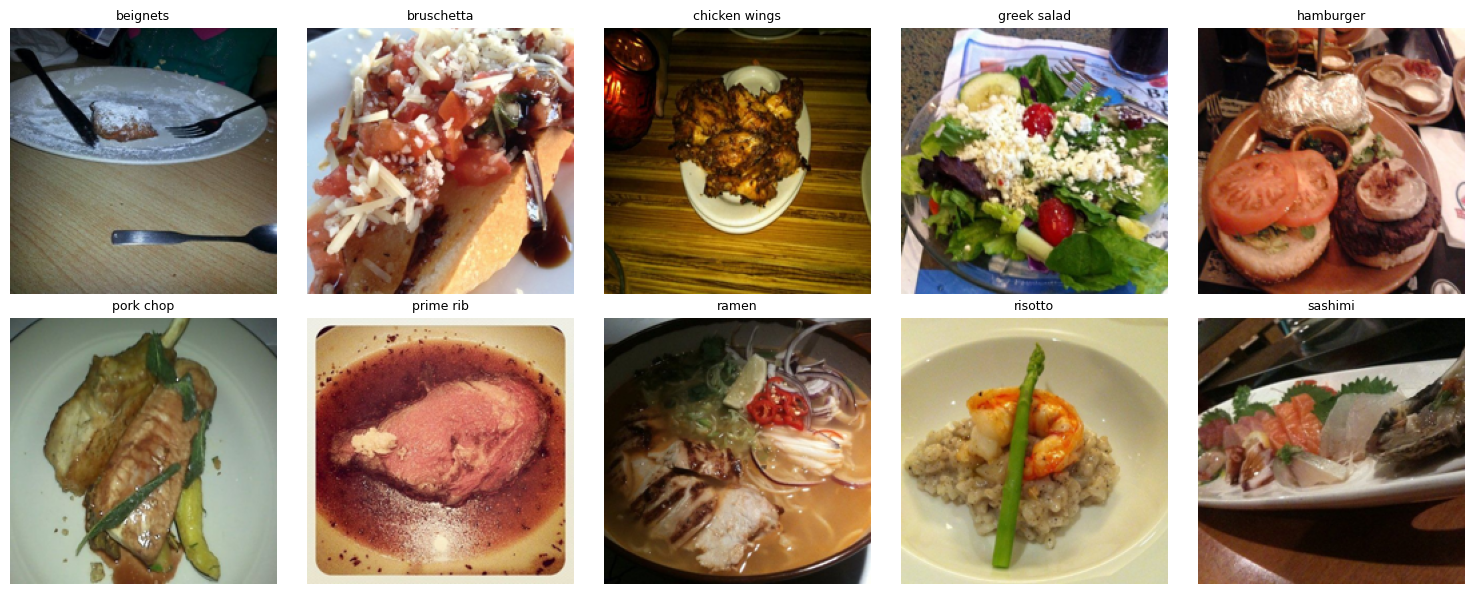

In [3]:
# Structure here is data/food101/{class}/NNN.jpg — no extra "images/" dir.
image_paths = []
labels = []

for class_dir in sorted(FOOD_DIR.iterdir()):
    if class_dir.is_dir():
        imgs = sorted(class_dir.glob("*.jpg"))
        image_paths.extend(imgs)
        labels.extend([class_dir.name] * len(imgs))

print(f"Images: {len(image_paths)}  |  Classes: {len(set(labels))}")

os.makedirs("artifacts", exist_ok=True)
unique_labels = sorted(set(labels))[:10]
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, lbl in enumerate(unique_labels):
    idx = labels.index(lbl)
    img = Image.open(image_paths[idx]).resize((200, 200))
    axes[i // 5][i % 5].imshow(img)
    axes[i // 5][i % 5].set_title(lbl.replace("_", " "), fontsize=9)
    axes[i // 5][i % 5].axis("off")
plt.tight_layout()
plt.savefig("artifacts/food_sample_grid.png", dpi=100)
plt.show()

## Preprocessing — CLIP embeddings

In [4]:
from transformers import CLIPProcessor, CLIPModel
from sklearn.model_selection import train_test_split

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()

def get_image_embedding(path):
    img = Image.open(path).convert("RGB")
    inputs = clip_proc(images=img, return_tensors="pt").to(device)
    with torch.no_grad():
        feat = clip_model.get_image_features(**inputs)
    return feat.cpu().numpy()[0]

# Stratified split so every class shows up in both gallery and test.
idx_paths, tst_paths, idx_labels, tst_labels = train_test_split(
    image_paths, labels, test_size=0.3, stratify=labels, random_state=7
)

print(f"Gallery: {len(idx_paths)}  Test: {len(tst_paths)}")
print("Embedding gallery (CPU, takes ~1-2 min)...")
# TODO batch this if I rerun on more data, single-image forward is wasteful
index_embs = np.array([get_image_embedding(p) for p in tqdm(idx_paths)])
print(f"Index shape: {index_embs.shape}")

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Gallery: 140  Test: 60
Embedding gallery (CPU, takes ~1-2 min)...


  0%|          | 0/140 [00:00<?, ?it/s]

  1%|          | 1/140 [00:00<00:51,  2.69it/s]

  1%|▏         | 2/140 [00:00<00:37,  3.64it/s]

... (67 outputs left out)

 99%|█████████▊| 138/140 [00:11<00:00, 15.23it/s]

100%|██████████| 140/140 [00:11<00:00, 15.09it/s]

100%|██████████| 140/140 [00:11<00:00, 12.38it/s]

Index shape: (140, 512)


## modeling — nearest-neighbor retrieval

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter

def predict_top_k(img_path, k=5):
    emb = get_image_embedding(img_path).reshape(1, -1)
    sims = cosine_similarity(emb, index_embs)[0]
    top_indices = sims.argsort()[::-1][:k]
    top_labels  = [idx_labels[i] for i in top_indices]
    top_scores  = sims[top_indices]
    # nearest-neighbor (k=1) for top-1, full list for top-k membership check
    top1 = top_labels[0]
    return top1, list(zip(top_labels, top_scores))

top1_correct, top5_correct = 0, 0
per_class_total = Counter()
per_class_hit   = Counter()

for path, true_label in tqdm(list(zip(tst_paths, tst_labels)), total=len(tst_paths)):
    top1, top5 = predict_top_k(path, k=5)
    per_class_total[true_label] += 1
    if top1 == true_label:
        top1_correct += 1
        per_class_hit[true_label] += 1
    if true_label in [l for l, _ in top5]:
        top5_correct += 1

n = len(tst_paths)
print(f"\nN test = {n}")
print(f"Top-1 accuracy: {top1_correct/n:.2%}")
print(f"Top-5 accuracy: {top5_correct/n:.2%}")
print("\nPer-class top-1:")
for cls in sorted(per_class_total):
    print(f"  {cls:14s} {per_class_hit[cls]:>2}/{per_class_total[cls]:<2}")

  0%|          | 0/60 [00:00<?, ?it/s]

  2%|▏         | 1/60 [00:00<00:06,  8.70it/s]

  3%|▎         | 2/60 [00:00<00:09,  6.44it/s]

  5%|▌         | 3/60 [00:00<00:07,  7.39it/s]

  7%|▋         | 4/60 [00:00<00:10,  5.58it/s]

  8%|▊         | 5/60 [00:00<00:10,  5.26it/s]

... (53 outputs left out)

 98%|█████████▊| 59/60 [00:12<00:00,  4.68it/s]

100%|██████████| 60/60 [00:12<00:00,  5.25it/s]

100%|██████████| 60/60 [00:12<00:00,  4.87it/s]


N test = 60
Top-1 accuracy: 85.00%
Top-5 accuracy: 100.00%

Per-class top-1:
  beignets        5/6 
  bruschetta      3/6 
  chicken_wings   5/6 
  greek_salad     6/6 
  hamburger       6/6 
  pork_chop       3/6 
  prime_rib       6/6 
  ramen           6/6 
  risotto         6/6 
  sashimi         5/6 


## LLM Call — nutrition summary and recipe variants

In [6]:
from openai import OpenAI
import re

client = OpenAI()

def _strip_fences(s: str) -> str:
    # Some providers still wrap JSON in ```json ... ``` even with response_format set.
    s = s.strip()
    if s.startswith("```"):
        s = re.sub(r"^```(?:json)?\s*", "", s)
        s = re.sub(r"\s*```$", "", s)
    return s

def get_recipe_and_nutrition(dish_name):
    prompt = (
        f'Dish: "{dish_name.replace("_", " ")}".\n'
        "Return JSON with keys: ingredients (list of 5-8 strings), "
        "calories (int, per serving estimate), "
        "variants (list of 2 short strings — e.g. a healthier version and a different cuisine spin)."
    )
    resp = client.chat.completions.create(
        model="gemini-flash-lite-latest",
        messages=[{"role": "user", "content": prompt}],
        temperature=0,
        response_format={"type": "json_object"},
    )
    return json.loads(_strip_fences(resp.choices[0].message.content))

if OPENAI_KEY:
    # Use a class we actually have, not "pizza".
    sample_dish = unique_labels[0]
    result = get_recipe_and_nutrition(sample_dish)
    print(f"Dish: {sample_dish}")
    print(json.dumps(result, indent=2))
else:
    print("Set OPENAI_API_KEY in .env to run the LLM demo")

Dish: beignets
{
  "ingredients": [
    "all-purpose flour",
    "granulated sugar",
    "active dry yeast",
    "whole milk",
    "unsalted butter",
    "large eggs",
    "powdered sugar",
    "vegetable oil for frying"
  ],
  "calories": 350,
  "variants": [
    "Baked whole wheat beignets",
    "Matcha-dusted Japanese style"
  ]
}


## Wrap-up

Zero-shot CLIP + cosine-NN is a surprisingly strong baseline for a small gallery. The per-class breakdown above shows which classes the embeddings already separate well and which collapse into each other (bruschetta and pork_chop are the weakest, no surprise, both have brown crusty surfaces on plates). With only 14 gallery images per class this is more of a sanity check than a real benchmark.

What would actually move this forward, in rough order of cost:

- Wire the USDA `food_nutrient.csv` lookup so calorie numbers stop being LLM hallucinations. I tried prompting first because it's one call, but the structured table is the right answer.
- Re-rank top-k with CLIP text prompts ("a photo of {dish}") and average with the image-NN score. Often fixes the taco/burrito-style confusions for free.
- Only if those two aren't enough: LoRA-finetune CLIP's vision tower on the full Food-101 set. A linear probe on frozen features is the cheaper experiment to run first.